# Ji et al. 2020 — Cutaneous Squamous Cell Carcinoma
## 01 · Preprocessing

Load malignant cells, threshold under-populated samples, select over-dispersed genes, **regress cell cycle** (the dataset-specific key to a clean manifold — cell cycle is the single largest program in this tumor), integrate samples with Harmony, embed, cluster, drop detached debris, and annotate SCC subtypes from marker expression + the Ji 2020 keratinocyte differentiation hierarchy (Basal / TSK / Differentiated).

In [1]:
import os, sys, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, frameon=True)

In [2]:
# import custom 3CA dataloader (scripts live at the CCCA root)
pth_ccca = os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..'))
sys.path.append(pth_ccca)
from scripts.load import load_CCCA_adata

In [3]:
# paths — the Category/ partition puts this notebook two levels deeper than Puram,
# so the repo root is four levels up; strip the run suffix (-N) for the input folder
name = os.path.split(os.getcwd())[1]                        # Ji2020_Skin-7
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]      # Skin
dset = re.sub(r'-\d+$', '', name)                          # Ji2020_Skin
pth      = os.path.join(*(['..']*4))
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', f'Data_{dset}')
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True)

In [4]:
# load dataset -> select malignant cells (UMI counts -> normalized + log1p by loader)
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
adata

Loading ../../../../../../data/unzip/CCCA/Data_Ji2020_Skin
Done.
Out[4]: 
AnnData object with n_obs × n_vars = 10598 × 32738
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype'
    uns: 'log1p'


AnnData object with n_obs × n_vars = 10598 × 32738
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype'
    uns: 'log1p'

In [5]:
# inspect per-sample malignant cell counts
n = adata.obs['sample'].value_counts()
print(n.sort_values())

sample
P3       27
P5       40
P9      268
P2      640
P6      729
P7     1012
P1     1064
P10    1130
P8     1472
P4     4216
Name: count, dtype: int64


In [6]:
# threshold under-populated samples by the low-tail count gap.
# Ji has a clean gap: 40 -> 268 (6.7x), so a ~100-cell cut cleanly drops the
# two tiny samples (P3=27, P5=40) that cannot support their own manifold arm.
n_sorted = n.sort_values()
ratios = n_sorted.values[1:] / n_sorted.values[:-1]
gap = int(np.argmax(ratios))
thr = int(np.sqrt(n_sorted.values[gap] * n_sorted.values[gap + 1]))
print(f'largest low-tail gap: {n_sorted.values[gap]} -> {n_sorted.values[gap+1]} '
      f'({ratios[gap]:.1f}x)  ->  threshold ~ {thr}')
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept samples:', sorted(keep.tolist()))
adata

largest low-tail gap: 40 -> 268 (6.7x)  ->  threshold ~ 103
kept samples: ['P1', 'P10', 'P2', 'P4', 'P6', 'P7', 'P8', 'P9']
Out[6]: 
AnnData object with n_obs × n_vars = 10531 × 32738
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype'
    uns: 'log1p'


AnnData object with n_obs × n_vars = 10531 × 32738
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype'
    uns: 'log1p'

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1443 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed: 1443


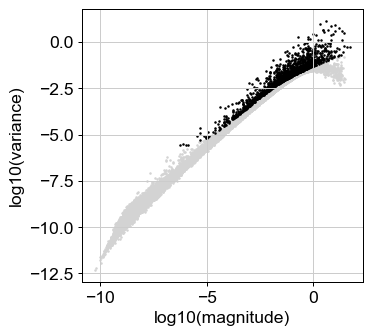

In [7]:
# filter genes + select over-dispersed features
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata, plot = True)
print('over-dispersed:', int(adata.var.highly_variable.sum()))

In [8]:
# score cell cycle (Tirosh/Regev S + G2M gene sets).
# In this tumor the cycling program is the single largest meta-program, so it
# otherwise dominates PC space and folds the manifold into a proliferation arch.
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7',
 'DTL','PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP',
 'CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN',
 'DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2',
 'CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB',
 'BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK',
 'CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR',
 'AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata,
    s_genes=[g for g in s_genes if g in adata.var_names],
    g2m_genes=[g for g in g2m_genes if g in adata.var_names])
print(adata.obs['phase'].value_counts())

phase
G1     5865
S      2839
G2M    1827
Name: count, dtype: int64


In [9]:
# regress out the cell-cycle signal, then PCA -> Harmony integrate samples
sc.pp.regress_out(adata, ['S_score', 'G2M_score'])
sc.pp.pca(adata, n_comps = 50)
sce.pp.harmony_integrate(adata, 'sample', theta = 2, max_iter_harmony = 20)

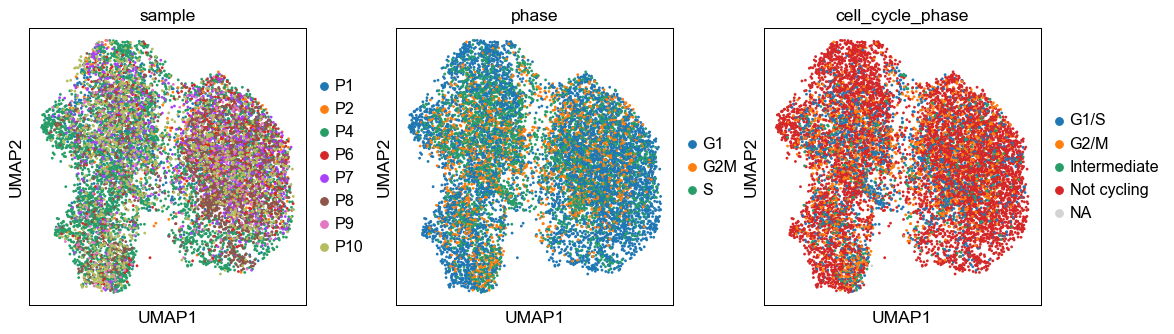

In [10]:
# nearest neighbors -> UMAP -> visual inspection of mixing + cycling
# n_pcs=20 sits on the scree plateau (elbow ~PC4-6); matches the 10x precedent scale.
c = ['sample', 'phase', 'cell_cycle_phase']
sc.pp.neighbors(adata, n_pcs = 20, use_rep = 'X_pca_harmony')
sc.tl.umap(adata, min_dist = 0.4, spread = 1.0)
sc.pl.umap(adata, color = c, size = 20, ncols = 3)

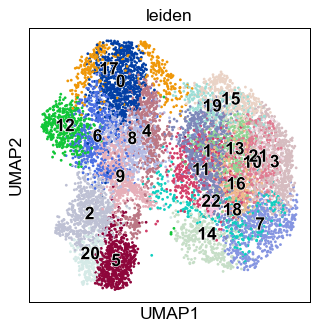

In [11]:
# cluster cells -> visual inspection (isolate any detached debris)
sc.tl.leiden(adata, resolution = 1.5, random_state = 0)
sc.pl.umap(adata, color = 'leiden', size = 20,
           legend_loc = 'on data', legend_fontoutline = True)

In [12]:
# drop detached clusters: build a UMAP radius graph at 6x the median
# nearest-neighbour distance, keep the largest connected component.
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.sparse import csr_matrix
X = adata.obsm['X_umap']
nn = NearestNeighbors(n_neighbors = 2).fit(X)
d, _ = nn.kneighbors(X)
r = 6 * np.median(d[:, 1])
rg = NearestNeighbors(radius = r).fit(X).radius_neighbors_graph(X)
ncc, lbl = connected_components(csr_matrix(rg), directed = False)
keep_lbl = np.bincount(lbl).argmax()
detached = adata.obs_names[lbl != keep_lbl]
print(f'radius={r:.2f}  components={ncc}  detached cells={len(detached)}')
adata = adata[lbl == keep_lbl].copy()
adata

radius=0.26  components=10  detached cells=13
Out[12]: 
AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'phase_colors', 'cell_cycle_phase_colors', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'


AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'phase_colors', 'cell_cycle_phase_colors', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

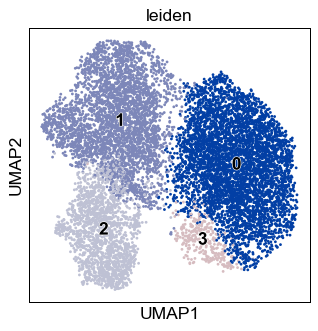

In [13]:
# re-cluster the connected manifold at low resolution -> visual inspection
sc.tl.leiden(adata, resolution = 0.35, random_state = 0)
sc.pl.umap(adata, color = 'leiden', size = 20,
           legend_loc = 'on data', legend_fontoutline = True)

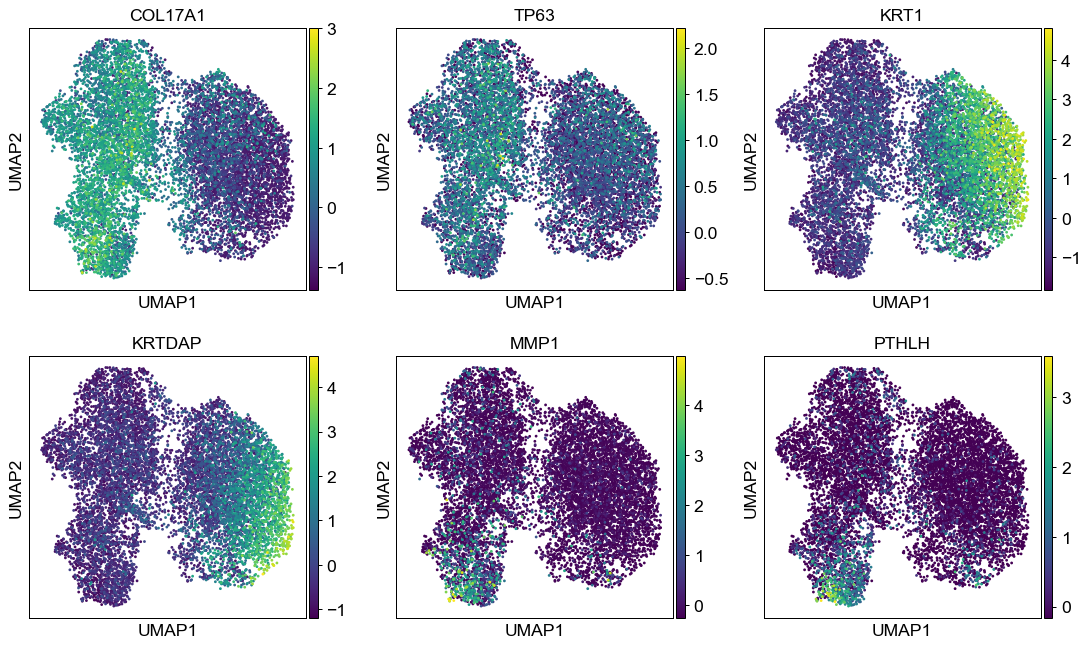

In [14]:
# subtype markers (Ji 2020 keratinocyte hierarchy + canonical SCC panels)
# Basal/progenitor: COL17A1, TP63, KRT5 ; Differentiated: KRT1, KRT10, KRTDAP ;
# TSK (tumor-specific keratinocyte, invasive leading edge): MMP1/10, PTHLH, LAMC2
c = ['COL17A1', 'TP63', 'KRT1', 'KRTDAP', 'MMP1', 'PTHLH']
sc.pl.umap(adata, color = c, size = 20, ncols = 3, cmap = 'viridis')

In [15]:
# assign each Leiden cluster to a subtype by its dominant marker program.
# Score the three programs per cluster (mean expression of present markers), and
# read Gast/pSom developmental modules (scored in 03) qualitatively from geography.
panels = {
    'Basal'        : ['COL17A1', 'TP63', 'KRT5'],
    'Differentiated': ['KRT1', 'KRT10', 'KRTDAP'],
    'TSK'          : ['MMP1', 'MMP10', 'PTHLH', 'LAMC2']}
prog = pd.DataFrame(index = sorted(adata.obs.leiden.unique(), key = int))
for lab, gs in panels.items():
    gs = [g for g in gs if g in adata.var_names]
    sc.tl.score_genes(adata, gs, score_name = f'_{lab}')
    prog[lab] = adata.obs.groupby('leiden', observed=True)[f'_{lab}'].mean()
print(prog.round(3))

   Basal  Differentiated    TSK
0 -0.305           0.721 -0.090
1  0.280          -0.638 -0.049
2  0.312          -0.732  0.352
3 -0.199           0.191 -0.084


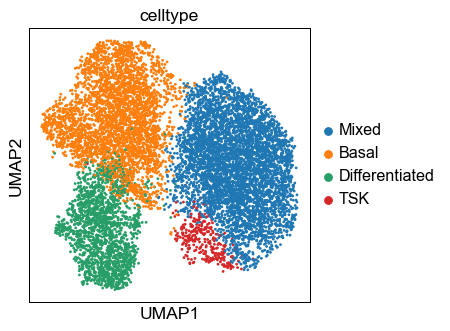

In [16]:
# Cluster 0 co-expresses Gast+pSom developmental modules (convergence hub) on a
# differentiated-keratinocyte body; 1 = Basal arm; 3 = pSom/TSK arm; 2 = Crest-high
# intermediate. Label the hub 'Mixed' (its role: module-convergence zone), matching
# the Puram naming for the Gast/pSom-overlap population that steps 04-05 run on.
celltype_dict = {
    '0' : 'Mixed',          # Gast+pSom convergence hub (differentiated body)
    '1' : 'Basal',          # COL17A1/TP63 basal-progenitor arm
    '2' : 'Differentiated', # Crest-high differentiated intermediate
    '3' : 'TSK'}            # MMP/PTHLH tumor-specific keratinocyte (pSom arm)
adata.obs['celltype'] = adata.obs.leiden.map(celltype_dict).astype('category')
sc.pl.umap(adata, color = 'celltype', size = 20)

In [17]:
# save processed data to h5ad file
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved', os.path.join(pth_out, 'processed.h5ad'))

saved ../../../../../../data/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/processed.h5ad


saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/samples.pdf


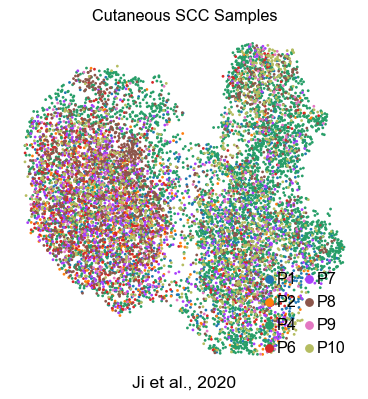

In [18]:
# save sample-integration figure (Gate 1 evidence: mixed + continuous)
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'sample', size = 20,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, ncol = 2, frameon = False,
          loc = 'lower right', columnspacing = .5, handletextpad = .25)
ax.set_title('Cutaneous SCC Samples', size = 13)
ax.text(.5, -.05, 'Ji et al., 2020', ha = 'center', transform = ax.transAxes)
fn = os.path.join(pth_fig, 'samples.pdf')
plt.savefig(fn, bbox_inches = 'tight'); print('saved', fn)